# 6 · Does a third frame tell whether a motion goes on?

The published search carries half the motion it finds between received frames N-2 and N on
to N+1 - it assumes whatever moved keeps moving at the same speed. Notebook 4 found where
that costs most: a scroll that stops between N and N+1 is carried on, and half of what an
oracle could gain over the search is knowing when that happens. Two frames cannot show it.
A third might: a scroll that is slowing down moved further from N-4 to N-2 than from N-2 to N.

The client can have that for nothing. The search's motion for N-4 -> N-2 is the one it found
a received frame ago; keeping it per tile is two numbers. So this notebook asks, **before
any network is trained**, how much the motion history is worth:

- **the ceiling**: per tile, the share of the newest motion that best makes N+1 - from
  repeat (none) through the search's half to all of it. It sees N+1;
- **what the history shows**: how the best share moves with how fast the motion was a pair
  earlier;
- **rules that need no fitting**: constant acceleration, exponential slowing down (a flick),
  and stopping after a slowdown - physics, not learning;
- **tables fitted on the train clips**: per bin of a few features, the share that scores best.
  A table is what a small network on the same features could learn at most, and nothing it
  does is hidden. One that sees two frames only (the speed, how well it matched) is the
  control: if it gains as much, the history is not what helps.

Every method decides one number per tile - how much of the newest motion to carry - so
every picture stays N moved by one motion, as sharp as the search's. On whole frames: the
113 validation clips rebuilt and cut into the client's 328x188 tiles, as in notebook 4,
and all 748 train clips for fitting.

Steps:

1. **Data** - the motion history of every tile, and the score of every share.
2. **The ceiling** - per tile, the best share.
3. **What the history shows** - the best share by how the motion changed.
4. **Rules** - with no fitting.
5. **Fitted tables** - two frames against three and four.
6. **By kind**.
7. **One wheel-scrolled clip**, frame by frame.

Nothing is exported. Needs: `00_data_preprocess.ipynb` and the sources it read.

| | how much of the newest motion it carries | fitted? | sees |
| --- | --- | --- | --- |
| repeat | none | no | - |
| published search | ½, none if the tile is still | no | N-2, N |
| constant acceleration | ½ + ⅜ (1 - r), r = the older motion over the newest | no | N-4, N-2, N |
| exponential slowing | λ² / (λ + 1), λ = 1/√r: a flick's decay | no | N-4, N-2, N |
| stop after a slowdown | none if r ≥ 2, else ½ | no | N-4, N-2, N |
| table, two frames | per bin of speed and match cost | on train | N-2, N |
| table, three / four frames | per bin of r (and r of the pair before) | on train | N-6 ... N |
| oracle | the best of 17 shares, per tile | not a model: reads N+1 | N+1 |

In [1]:
"""Settings."""

import time

import matplotlib.pyplot as plt
import numpy as np
import torch

from helpers import clips, history, metrics, models, runs, show, training
from helpers.history import GRID, along
from helpers.training import DEVICE

RADIUS, SCALE, SHARPNESS, STRIDE, STILL = 4, 2, 10.0, 2, 0.1   # notebook 3's published search
DEPTH = 3          # pairs of history: N-2 -> N, N-4 -> N-2, N-6 -> N-4
EVERY = 1          # a sample at every received frame N that has DEPTH pairs before it
WIDE = 8           # the history is read with a search reaching ±16 stream px: a wheel notch moves further
CAP = 50.0         # tables are fitted on wPSNR capped here: past it an error is invisible, and a tile that
                   # barely changed would otherwise outweigh every changed one
MIN_COUNT = 200    # a fitted bin with fewer moving train tiles keeps the published share
CACHE = training.CHECKPOINT_DIR / "history"   # the tables, so a rerun need not rebuild 860 clips
SEED = 0
training.seed_everything(SEED)

## 1. Data

Every source of a split rebuilt from the manifest (`clips.rebuild`) and cut into the
client's tiles (`clips.plan`). For each tile, the search on every received pair
(`history.pairs`, the published search carrying the whole motion, ungated), and at every
received frame N from N = 6 on: the motion of the last three pairs, and N moved on by each
of 17 shares of the newest motion, scored against N+1 over the region the client keeps
(`history.load`). No pictures are kept - the train split fits in memory as numbers.

The history is read with a second search reaching twice as far (±16 stream px, `WIDE`): a
wheel notch moves up to 18 px between received frames just before it stops, past the
published search's ±8, and a motion measured short there reads as no slowdown at all. The
motion carried is still the published search's.

In [2]:
manifest = training.load_manifest()
training.describe(manifest)
STEP = runs.received_every(manifest)
search = models.TileSearch(RADIUS, SCALE, SHARPNESS, STRIDE, 1 / STEP, still=STILL).to(DEVICE).eval()
wide = models.TileSearch(WIDE, SCALE, SHARPNESS, STRIDE, 1 / STEP).to(DEVICE).eval()
CACHE.mkdir(parents=True, exist_ok=True)

KINDS = ["page", "desktop", "photo", "screen", "video", "pointer"]
data, masks = {}, {}
for split in ("train", "val"):
    started = time.time()
    path = CACHE / f"{split}_r{RADIUS}_s{STRIDE}_w{WIDE}_d{DEPTH}_e{EVERY}.npz"
    if path.exists() and path.stat().st_mtime > (training.DATA_DIR / "manifest.json").stat().st_mtime:
        data[split] = history.restore(path)
    else:
        data[split] = history.load(manifest, split, search, DEPTH, EVERY, wide=wide)
        history.save(path, data[split])
    masks[split] = history.groups(manifest, split, data[split])
    for kind in KINDS:
        masks[split][f"{kind}, changed"] = masks[split][kind] & masks[split]["changed"]
    masks[split]["moving"] = data[split]["still"][:, 0] >= STILL   # the gate is open: a share is chosen
    group = masks[split]
    print(f"{split:5} {group['all'].sum():6} tiles, {group['changed'].sum():6} changed "
          f"({', '.join(f'{kind} {group[f"{kind}, changed"].sum()}' for kind in KINDS)}), "
          f"{group['moving'].sum()} moving between N-2 and N "
          f"from {len(set(data[split]['source']))} clips in {time.time() - started:.0f}s; "
          f"left out (smaller than a tile): {len(data[split]['skipped'])}")

device  cuda NVIDIA GeForce RTX 3090
stream  x2 down from a 1280x720 window, 60 fps
run     96 px (64 px + a halo of 16), 8 frames each
stream  every 2th frame received - the inputs are frames N-2 and N, the target N+1 (2x frame generation)
train  53775 tiles,  20864 changed (page 4681, desktop 1934, photo 3597, screen 3180, video 7472, pointer 2387), 31214 moving between N-2 and N from 678 clips in 631s; left out (smaller than a tile): 0
val    17190 tiles,   5553 changed (page 1307, desktop 184, photo 954, screen 1654, video 1454, pointer 568), 9077 moving between N-2 and N from 232 clips in 224s; left out (smaller than a tile): 0


In [3]:
"""The table holds the published search: at a share of ½ where the tile moved, repeat where
the gate says it is still - the same pictures as `models.Motion` with the published search,
run beside it on every tile."""

for split, table in data.items():
    moving = table["still"][:, 0] >= STILL
    expected = np.where(moving, table["scores"][:, len(GRID) // 2], table["scores"][:, 0])
    gap = np.abs(expected - table["published"])[masks[split]["changed"]]
    print(f"{split:5} published search against the table, changed tiles: largest gap {gap.max():.4f} dB, "
          f"mean {table['published'][masks[split]['changed']].mean():.2f} dB")
    assert gap.max() < 0.01, "the table does not hold the published search"

train published search against the table, changed tiles: largest gap 0.0000 dB, mean 31.64 dB
val   published search against the table, changed tiles: largest gap 0.0000 dB, mean 31.46 dB


## 2. The ceiling

**Three columns, and why the third.** *Changed* is every notebook's headline: tiles where
N+1 differs from N. It cannot judge a stop: where a motion stops, N+1 is N, so the tile is
not changed - the scores of changed tiles leave out exactly the tiles where stopping was
right, and count every one where it was wrong. *All* has them, but there a tile that barely
changed scores 60-80 dB and a fraction of a pixel moves it by tens of dB nobody can see.
*Moving* is the tiles every method here decides on - the gate is open, something moved
between N-2 and N - each capped at 50 dB, past which an error is invisible. It is the fair
one for whether to go on, and the one the tables are fitted on (on the train clips).

Per tile, the share of the newest motion whose picture is closest to N+1. Every method here
decides that one number, so this is the most any of them can get, and it sees the answer.
Beside it, the choice notebook 4 bounded: only repeat or the search's half, per tile.

wPSNR (dB), vs the published search                changed               all   moving, ≤ 50 dB
repeat                                       28.35 (-3.11)     61.41 (-0.56)     36.65 (-1.44)
published search                             31.46 (+0.00)     61.97 (+0.00)     38.09 (+0.00)
oracle: repeat or ½, per tile                31.97 (+0.51)     62.59 (+0.61)     38.73 (+0.64)
oracle: best of 17 shares, per tile          33.27 (+1.81)     63.01 (+1.04)     39.51 (+1.42)


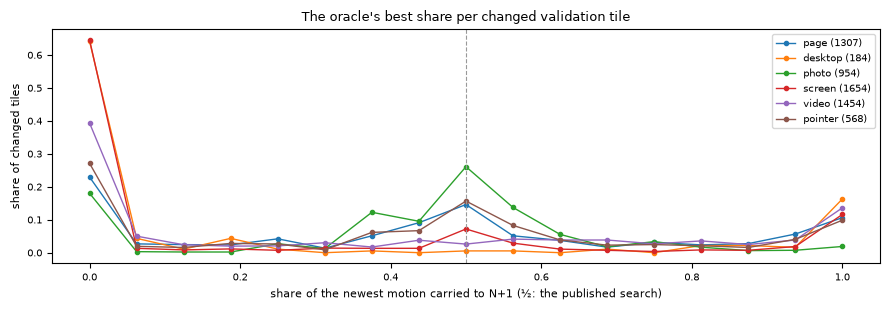

In [4]:
GROUPS = ["changed", "all", "moving", *[f"{kind}, changed" for kind in KINDS]]
HALF = len(GRID) // 2
results = {}


def record(name, values, split="val"):
    """Per group, the mean of (S,) per-tile scores."""
    results[name] = {group: float(values[masks[split][group]].mean()) for group in GROUPS}
    results[name]["moving"] = float(np.minimum(values, CAP)[masks[split]["moving"]].mean())


def chosen(table, share):
    """(S,) the per-tile score of carrying `share` (S,) of the newest motion."""
    index = np.clip(np.rint(np.asarray(share) * (len(GRID) - 1)).astype(int), 0, len(GRID) - 1)
    return table["scores"][np.arange(len(index)), index]


def show_results(names, base="published search"):
    print(f"{'wPSNR (dB), vs the published search':<40}{'changed':>18}{'all':>18}{'moving, ≤ 50 dB':>18}")
    for name in names:
        row = "".join(f"{results[name][g]:10.2f} ({results[name][g] - results[base][g]:+5.2f})"
                      for g in ("changed", "all", "moving"))
        print(f"{name:<40}{row}")


val = data["val"]
baseline = {"repeat": val["scores"][:, 0], "published search": val["published"],
            "oracle: repeat or ½, per tile": val["scores"][:, [0, HALF]].max(1),
            "oracle: best of 17 shares, per tile": val["scores"].max(1)}
for name, values in baseline.items():
    record(name, values)
show_results(["repeat", "published search", "oracle: repeat or ½, per tile", "oracle: best of 17 shares, per tile"])

best = GRID[val["scores"].argmax(1)]
fig, ax = plt.subplots(figsize=(9, 3.2))
for kind in KINDS:
    picked = best[masks["val"][f"{kind}, changed"]]
    ax.plot(GRID, [(np.isclose(picked, g)).mean() for g in GRID], "o-", ms=3, lw=1, label=f"{kind} ({len(picked)})")
ax.axvline(0.5, color="0.6", lw=0.8, ls="--")
ax.set_xlabel("share of the newest motion carried to N+1 (½: the published search)", fontsize=8)
ax.set_ylabel("share of changed tiles", fontsize=8)
ax.set_title("The oracle's best share per changed validation tile", fontsize=9)
ax.tick_params(labelsize=7)
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

## 3. What the history shows

`r`, for each tile, is how far the motion one pair earlier (N-4 -> N-2) went along the newest
one (N-2 -> N), as a share of it, both read with the wide search: 1 for a steady motion, 2 for one that halved its speed, 0
for one that just started. If whether a motion goes on shows in the history, the best share
should fall below ½ as `r` grows. Each line is one bin of `r` on the moving, changed train
tiles: the mean wPSNR of every share against the published half. Left, the changed ones -
which leave out the stops; right, every moving one, capped at 50 dB.

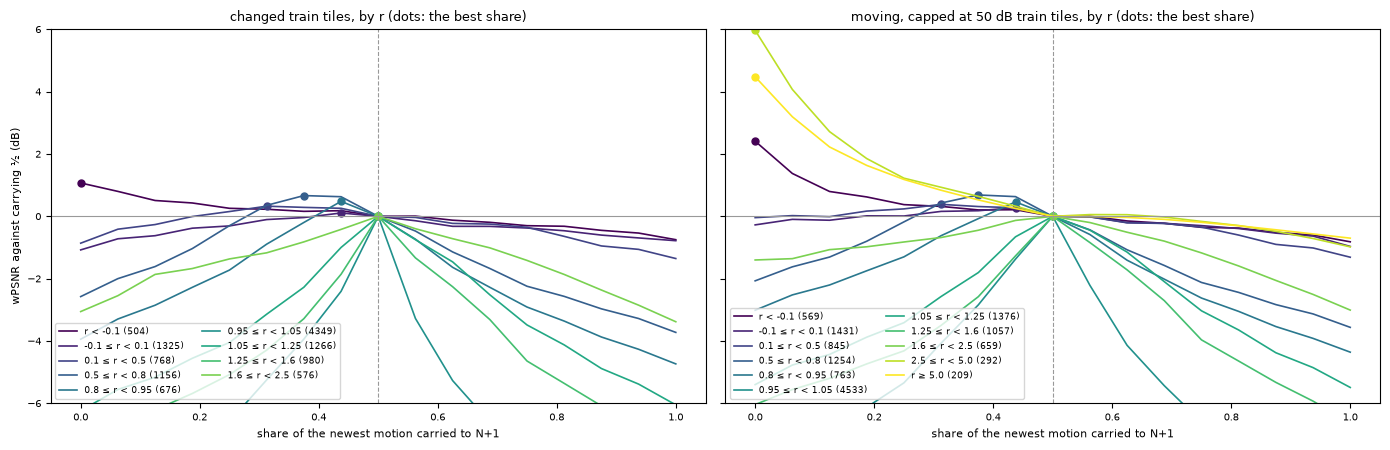

In [5]:
R_EDGES = [-0.1, 0.1, 0.5, 0.8, 0.95, 1.05, 1.25, 1.6, 2.5, 5.0]


def binned(values, edges):
    """Bin index of each value (0 .. len(edges)), and len(edges) + 1 for NaN."""
    return np.where(np.isnan(values), len(edges) + 1, np.digitize(np.nan_to_num(values, nan=0.0), edges))


train = data["train"]
moving_train = train["still"][:, 0] >= STILL
r_train = along(train, 1)
bins = binned(r_train, R_EDGES)
labels = [f"r < {R_EDGES[0]}"] + [f"{a} ≤ r < {b}" for a, b in zip(R_EDGES, R_EDGES[1:])] + \
         [f"r ≥ {R_EDGES[-1]}", "no newest motion"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
colours = plt.get_cmap("viridis")
capped = np.minimum(train["scores"], CAP)
for ax, (title, scores, among) in zip(axes, (("changed", train["scores"], masks["train"]["changed"]),
                                             ("moving, capped at 50 dB", capped, moving_train))):
    for b in range(len(R_EDGES) + 1):
        picked = moving_train & among & (bins == b)
        if picked.sum() < MIN_COUNT:
            continue
        curve = (scores[picked] - scores[picked][:, [HALF]]).mean(0)
        line, = ax.plot(GRID, curve, "-", lw=1.2, color=colours(b / len(R_EDGES)),
                        label=f"{labels[b]} ({picked.sum()})")
        ax.plot(GRID[curve.argmax()], curve.max(), "o", color=line.get_color(), ms=5)
    ax.axhline(0, color="0.6", lw=0.8)
    ax.axvline(0.5, color="0.6", lw=0.8, ls="--")
    ax.set_ylim(-6, 6)
    ax.set_xlabel("share of the newest motion carried to N+1", fontsize=8)
    ax.set_title(f"{title} train tiles, by r (dots: the best share)", fontsize=9)
    ax.tick_params(labelsize=7)
    ax.legend(fontsize=6.5, loc="lower left", ncol=2)
axes[0].set_ylabel("wPSNR against carrying ½ (dB)", fontsize=8)
fig.tight_layout()
plt.show()

## 4. Rules

Each is a share of the newest motion per tile, from the motions alone, with the published
gate: a tile whose two newest frames match at no motion gets none. Where the newest motion
is under a tenth of a pixel `r` is undefined and the rules carry ½.

- **constant acceleration**: the speed changes as much over the next frame as it did
  between the two pairs' middles. Per display frame the pairs' speeds are m0/2 at N-1 and
  m1/2 at N-3; carried to N+½ that is ½ + ⅜ (1 - r) of m0. It lost on the 30 fps set in
  notebook 1's history, by carrying on accelerations that ended;
- **exponential slowing**: a flick's speed decays by a constant factor; r gives it, λ = 1/√r
  per display frame, and the motion from N to N+1 is λ²/(λ+1) of the newest pair's. Where
  r ≤ 0 nothing decays and it carries ½;
- each of those **for slowing only** - never more than ½ - since speeding up is rarer and an
  overshoot as bad as a stop missed;
- **stop after a slowdown**: none of the motion if the pair before went at least twice as far.

In [6]:
def moving(table):
    return table["still"][:, 0] >= STILL


def gated(table, share):
    return np.where(moving(table), share, 0.0)


def acceleration(table):
    return np.nan_to_num(np.clip(0.5 + 0.375 * (1 - along(table, 1)), 0, 1), nan=0.5)


def exponential(table):
    r = along(table, 1)
    with np.errstate(invalid="ignore", divide="ignore", over="ignore"):
        decay = 1 / np.sqrt(np.where(r > 0, r, np.nan))
        share = np.clip(decay ** 2 / (decay + 1), 0, 1)
    return np.nan_to_num(share, nan=0.5)


methods = {
    "constant acceleration": lambda t: gated(t, acceleration(t)),
    "constant acceleration, slowing only": lambda t: gated(t, np.minimum(acceleration(t), 0.5)),
    "exponential slowing": lambda t: gated(t, exponential(t)),
    "exponential slowing, slowing only": lambda t: gated(t, np.minimum(exponential(t), 0.5)),
    "stop after a slowdown (r ≥ 2)": lambda t: gated(t, np.where(along(t, 1) >= 2, 0.0, 0.5)),
    "stop after a slowdown (r ≥ 3)": lambda t: gated(t, np.where(along(t, 1) >= 3, 0.0, 0.5)),
}
for name, method in methods.items():
    record(name, chosen(val, method(val)))
show_results(["repeat", "published search", *methods])

wPSNR (dB), vs the published search                changed               all   moving, ≤ 50 dB
repeat                                       28.35 (-3.11)     61.41 (-0.56)     36.65 (-1.44)
published search                             31.46 (+0.00)     61.97 (+0.00)     38.09 (+0.00)
constant acceleration                        30.78 (-0.68)     61.83 (-0.15)     37.81 (-0.27)
constant acceleration, slowing only          30.95 (-0.51)     61.89 (-0.09)     37.92 (-0.17)
exponential slowing                          30.72 (-0.74)     61.75 (-0.22)     37.74 (-0.35)
exponential slowing, slowing only            31.01 (-0.45)     61.85 (-0.12)     37.91 (-0.17)
stop after a slowdown (r ≥ 2)                31.50 (+0.04)     62.07 (+0.10)     38.20 (+0.11)
stop after a slowdown (r ≥ 3)                31.47 (+0.01)     62.04 (+0.07)     38.16 (+0.07)


## 5. Fitted tables

Per bin of a few features, the share with the best mean wPSNR over the moving train tiles
(changed or not - the client cannot tell which), each tile's score capped at `CAP`: a tile
that barely changed scores 60-80 dB whatever is done to it within a fraction of a pixel, and
uncapped those few dB of invisible difference outweigh every changed tile - a first run
fitted that way chose repeat for every r under 0.95, 2.8 dB under the half on the changed
tiles there. A bin with fewer than `MIN_COUNT` of them keeps ½. Scored on the validation clips, which no bin was fitted on.

- **two frames**: the newest motion's speed and its least cost (how well N-2 moved onto N) -
  what the published search already has. The control: whatever this gains, history is not
  needed for;
- **three frames**: r; r and the speed;
- **four frames**: r and the r of the pair before that (N-6 -> N-4 along the newest); and the
  speed as well.

In [7]:
SPEED_EDGES = [0.5, 1.0, 2.0, 4.0, 8.0]          # stream pixels between received frames
COST_EDGES = [0.5, 1.0, 2.0, 4.0, 8.0]           # least cost, luma levels
R2_EDGES = [0.1, 0.8, 1.25, 2.5]


def speed(table):
    return np.linalg.norm(table["motion"][:, 0], axis=1)


FEATURES = {
    "table, two frames: speed × match": lambda t: binned(speed(t), SPEED_EDGES) * 16 + binned(t["best"][:, 0], COST_EDGES),
    "table, three frames: r": lambda t: binned(along(t, 1), R_EDGES),
    "table, three frames: r × speed": lambda t: binned(along(t, 1), R_EDGES) * 16 + binned(speed(t), SPEED_EDGES),
    "table, four frames: r × r before": lambda t: binned(along(t, 1), R_EDGES) * 16 + binned(along(t, 2), R2_EDGES),
    "table, four frames: r × r before × speed": lambda t: (binned(along(t, 1), R_EDGES) * 256
                                                          + binned(along(t, 2), R2_EDGES) * 16
                                                          + binned(speed(t), SPEED_EDGES)),
}


def fit(keys, table, mask):
    """{bin: share} - per bin with MIN_COUNT tiles of `mask`, the share with the best mean score."""
    shares = {}
    for key in np.unique(keys[mask]):
        picked = mask & (keys == key)
        if picked.sum() >= MIN_COUNT:
            shares[int(key)] = float(GRID[np.minimum(table["scores"][picked], CAP).mean(0).argmax()])
    return shares


def table_method(features, shares):
    return lambda t: gated(t, np.array([shares.get(int(k), 0.5) for k in features(t)]))


fitted = {}
print(f"{'':<44}{'bins':>6}{'train moving, ≤ 50 dB':>22}")
for name, features in FEATURES.items():
    shares = fit(features(train), train, moving_train)
    fitted[name] = shares
    methods[name] = table_method(features, shares)
    record(name, chosen(val, methods[name](val)))
    fitted_on = moving_train
    in_sample = np.minimum(chosen(train, methods[name](train)), CAP)[fitted_on].mean()
    print(f"{name:<44}{len(shares):6}{in_sample:10.2f} ({in_sample - np.minimum(train['published'], CAP)[fitted_on].mean():+5.2f})")
print()
show_results(["published search", *FEATURES, "oracle: repeat or ½, per tile", "oracle: best of 17 shares, per tile"])

print("\nthe three-frame table's share per bin of r:")
for b, share in sorted(fitted["table, three frames: r"].items()):
    print(f"  {labels[b]:<18} {share:.3f}")

                                              bins train moving, ≤ 50 dB
table, two frames: speed × match                23     37.28 (+0.07)
table, three frames: r                          12     37.40 (+0.19)
table, three frames: r × speed                  22     37.31 (+0.10)
table, four frames: r × r before                19     37.31 (+0.10)
table, four frames: r × r before × speed        11     37.23 (+0.01)

wPSNR (dB), vs the published search                changed               all   moving, ≤ 50 dB
published search                             31.46 (+0.00)     61.97 (+0.00)     38.09 (+0.00)
table, two frames: speed × match             31.50 (+0.04)     62.00 (+0.03)     38.15 (+0.06)
table, three frames: r                       31.51 (+0.05)     62.08 (+0.11)     38.23 (+0.14)
table, three frames: r × speed               31.55 (+0.09)     62.03 (+0.05)     38.20 (+0.12)
table, four frames: r × r before             31.32 (-0.14)     61.95 (-0.03)     38.05 (-0.04)
table, four

## 6. By kind

Validation tiles by kind of source and around the pointer: the changed ones, then the
moving ones capped at 50 dB.

In [8]:
shown = ["repeat", "published search", "constant acceleration, slowing only", "exponential slowing, slowing only",
         "table, two frames: speed × match", "table, three frames: r", "table, four frames: r × r before",
         "oracle: repeat or ½, per tile", "oracle: best of 17 shares, per tile"]
print(f"{'wPSNR (dB), changed':<44}" + "".join(f"{kind:>10}" for kind in KINDS))
for name in shown:
    print(f"{name:<44}" + "".join(f"{results[name][f'{kind}, changed']:10.2f}" for kind in KINDS))

print(f"\n{'wPSNR (dB), moving, capped at 50 dB':<44}" + "".join(f"{kind:>10}" for kind in KINDS))
for name in shown:
    print(f"{name:<44}" + "".join(
        f"{np.minimum(chosen(val, methods[name](val)) if name in methods else baseline[name], CAP)[masks['val']['moving'] & masks['val'][kind]].mean():10.2f}"
        for kind in KINDS))

wPSNR (dB), changed                               page   desktop     photo    screen     video   pointer
repeat                                           24.66     29.30     23.46     32.39     30.15     24.71
published search                                 29.29     29.33     31.03     34.16     30.89     29.22
constant acceleration, slowing only              28.48     29.43     29.95     33.67     30.91     28.68
exponential slowing, slowing only                28.48     29.39     30.15     33.78     30.90     28.71
table, two frames: speed × match                 29.26     29.34     31.10     34.17     31.00     29.01
table, three frames: r                           29.64     29.35     31.37     33.84     30.88     29.51
table, four frames: r × r before                 29.45     29.41     31.40     33.43     30.79     29.47
oracle: repeat or ½, per tile                    30.12     29.47     31.71     34.30     31.49     29.82
oracle: best of 17 shares, per tile              32.62 

## 7. One wheel-scrolled clip

Notebook 4's clip: a page scrolled by the wheel, every generated frame of it. On top, the
scroll as the scene recorded it, with the guesses at each generated frame - repeat, the
search's half, and the best history method's share (the mean over the moving tiles). Below,
the whole frame's wPSNR of each, and of the oracle that picks the best share per tile.

the best history method on moving validation tiles: table, three frames: r


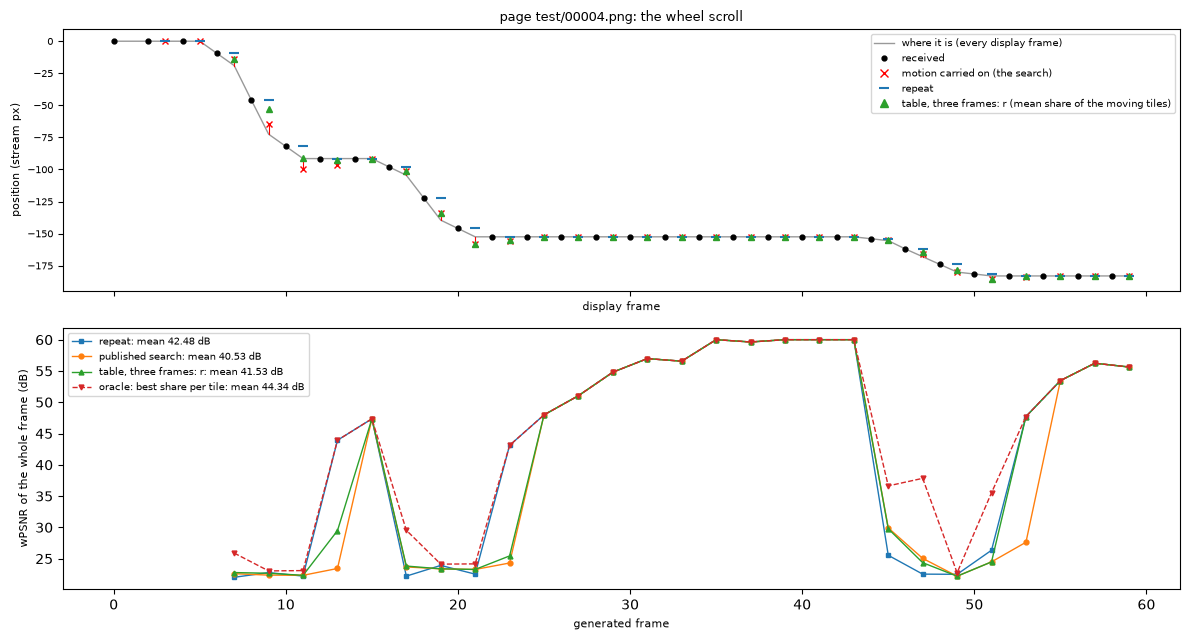

In [9]:
history_methods = [name for name in methods if "two frames" not in name]
BEST = max(history_methods, key=lambda name: results[name]["moving"])
print(f"the best history method on moving validation tiles: {BEST}")

source = next(s for s in manifest["splits"]["val"]["sources"] if (s.get("scene") or {}).get("background") == "wheel")
stream = clips.rebuild(source, manifest)
height, width = stream.shape[1:3]
layout, size = clips.plan(width, height)
motion, still, least = history.pairs(stream, search, layout, size, STEP)
reach = history.pairs(stream, wide, layout, size, STEP)[0]


def whole(made):
    """A frame put together from its tiles, each giving the region the client keeps."""
    frame = torch.zeros(3, height, width, device=DEVICE)
    for tile, (ix, iy, ox, oy, w, h) in zip(made, layout):
        frame[:, iy + oy:iy + oy + h, ix + ox:ix + ox + w] = tile[:, oy:oy + h, ox:ox + w]
    return frame[None]


names = ["repeat", "published search", BEST, "oracle: best share per tile"]
scores = {name: [] for name in names}
made_frames, guessed = [], []
with torch.no_grad():
    for n in range(DEPTH * STEP, len(stream) - 1, STEP):
        pairs = [n // STEP - 1 - k for k in range(DEPTH)]
        tiles = {"motion": motion[pairs].transpose(1, 0, 2), "wide": reach[pairs].transpose(1, 0, 2),
                 "still": still[pairs].T, "best": least[pairs].T}
        windows = np.stack([stream[[n, n + 1], iy:iy + size[0], ix:ix + size[1]] for ix, iy, *_ in layout])
        current, target = training.to_tensor(windows).unbind(1)
        newest = torch.as_tensor(tiles["motion"][:, 0], device=DEVICE)

        def made(share):
            return history.carried(current, newest, torch.as_tensor(share, device=DEVICE, dtype=torch.float32))

        every_share = torch.stack([made(np.full(len(layout), g)) for g in GRID], 1)
        kept_error = torch.stack([torch.stack([history.sample_wpsnr(
            clips.kept(every_share[t:t + 1, j], (oy, ox, h, w)), clips.kept(target[t:t + 1], (oy, ox, h, w)))[0]
            for j in range(len(GRID))]) for t, (ix, iy, ox, oy, w, h) in enumerate(layout)])
        oracle = every_share[torch.arange(len(layout)), kept_error.argmax(1)]
        share = methods[BEST](tiles)
        pictures = {"repeat": current, "published search": made(gated(tiles, np.full(len(layout), 0.5))),
                    BEST: made(share), "oracle: best share per tile": oracle}
        for name, picture in pictures.items():
            scores[name].append(min(60.0, metrics.wpsnr(whole(picture), whole(target))))
        made_frames.append(n + 1)
        guessed.append(share[moving(tiles)].mean() if moving(tiles).any() else 0.0)

scroll = np.array(source["scene"]["scroll"]) / manifest["scale"]
axis = int(np.abs(scroll[-1] - scroll[0]).argmax())
positions = scroll[:, axis]
fig, (top, bottom) = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
show.track(top, positions, STEP, 1 / STEP, f"{source['kind']} {source['file']}: the wheel scroll")
for n, share in zip(np.array(made_frames) - 1, guessed):
    top.plot(n + 1, positions[n] + share * (positions[n] - positions[n - STEP]), "^", color="tab:green", ms=4)
top.plot([], [], "^", color="tab:green", label=f"{BEST} (mean share of the moving tiles)")
top.legend(fontsize=7)
for (name, values), style in zip(scores.items(), ("s-", "o-", "^-", "v--")):
    bottom.plot(made_frames, values, style, ms=3.5, lw=1, label=f"{name}: mean {np.mean(values):.2f} dB")
bottom.set_ylabel("wPSNR of the whole frame (dB)", fontsize=8)
bottom.set_xlabel("generated frame", fontsize=8)
bottom.legend(fontsize=7)
fig.tight_layout()
plt.show()

## What it says

- **The history holds a little signal, mostly on drawn pages.** The best rule on the moving
  validation tiles is a table of `r` alone (three frames): **+0.14 dB over the published half**
  (+0.05 on the changed tiles). By kind, pages +0.63, around the pointer +0.52, desktops +0.60,
  photos +0.26 - and screens −0.10, video +0.06. Its shares: none where the motion went 2.5 times
  as far one pair earlier (a stop after a slowdown), half where it is steady, a little less where
  it is speeding up or has just started.
- **Four frames are not better than three.** r × r before is −0.04 dB on the moving validation
  tiles after +0.10 on the training ones; with the speed as well, +0.03. What a fourth frame
  seems to say about a stop does not hold up off the clips it was fitted on.
- **Physics loses.** Constant acceleration and exponential slowing lose to the half (−0.17 to
  −0.35 dB on the moving tiles, −0.45 to −0.74 on the changed): a wheel notch eases out over a few
  frames and then stops, and a smooth extrapolation of its speed is wrong both ways. Stopping
  outright after a slowdown is the rule that works: r ≥ 2 → none, +0.11 dB, nothing fitted.
- **It is the history, barely.** The control table, fitted the same way on what two frames give
  (speed, match cost), gains +0.06 dB on the validation tiles (+0.07 on the training ones); the
  three-frame table +0.14 (+0.19).
- **A fifth of choosing between repeat and the half, a tenth of the ceiling.** The per-tile oracle
  over repeat or ½ is +0.64 dB on the moving tiles, over all 17 shares +1.42. Most stops are not
  announced in the frames before - a notch ends, a drag is let go - and on the recordings what
  changes is mostly not one motion at all: the best share per tile is worth +0.24 dB on screens
  (42.92 against 42.68), against +3.4 on pages.
- **"Changed" cannot judge a stop.** A tile whose motion stopped has N+1 = N and is not changed,
  so a score over the changed tiles counts the stops a method misses and none it catches; the
  moving tiles, capped at 50 dB, are the fair column for whether a motion goes on.

So the history is worth about +0.1 dB on this set - +0.6 on the drawn pages that scroll by wheel
notches, nothing on recordings - from three frames and a table of 12 numbers. A network on the
same features could at most find that table; the client's own wheel and drag input is what
would announce the stops the frames never show.